# Twitter Sentiment Analysis — Group Project Report

We present a sentiment classifier for X (Twitter) posts. Our team compared a lexicon baseline, several classical machine-learning models and a set of neural networks, all trained on the same preprocessing and feature pipeline. The notebook below documents our data preparation, our features, every model we trained, our results and the mistakes our best model still makes.

##### Github Link <https://github.com/MAX9394/Twitter-Sentiment-Analysis>

## Project Overview

Our goal was to predict whether a tweet expresses positive or negative sentiment. Our team:

* built a reusable preprocessing and feature-extraction pipeline that uses NLTK stopwords and keeps negation words
* compared a lexicon baseline with Naive Bayes, Maximum Entropy, Decision Tree, Random Forest, XGBoost and SVM
* trained neural classifiers (logistic regression, MLP, LSTM and CNN) on the same data
* reused CNN penultimate-layer features with an SVM
* combined the models with majority voting
* evaluated every model on a held-out validation split and wrote test predictions
* examined misclassified tweets and demonstrated the final model on our own examples

We worked with a labelled corpus of tweets. The notebook uses NLTK's `twitter_samples`. The corpus provides 5,000 positive and 5,000 negative tweets; we use 4,000 per class for training and 1,000 per class for testing, matching the reference notebook's 80/20 split.

## Table of Contents

- [Setup: Imports and Configuration](#0)
- [1 - How We Prepared Our Data](#1)
- [2 - How We Preprocessed Tweets](#2)
- [3 - Our Corpus Statistics](#3)
- [4 - Our Exploratory Plots](#4)
- [5 - Our Feature Engineering](#5)
- [6 - Our Lexicon Baseline](#6)
- [7 - Our Classical Classifiers](#7)
    - [7.1 - Our Naive Bayes Model](#7-1)
    - [7.2 - Our Maximum Entropy Model](#7-2)
    - [7.3 - Our Decision Tree Model](#7-3)
    - [7.4 - Our Random Forest Model](#7-4)
    - [7.5 - Our XGBoost Model](#7-5)
    - [7.6 - Our Support Vector Machine](#7-6)
- [8 - Our Neural Classifiers](#8)
    - [8.1 - Our Logistic Regression Model](#8-1)
    - [8.2 - Our Multi-Layer Perceptron](#8-2)
    - [8.3 - Our LSTM Model](#8-3)
    - [8.4 - Our Convolutional Neural Network](#8-4)
- [9 - CNN Feature Extraction + SVM](#9)
- [10 - Our Majority-Vote Ensemble](#10)
- [11 - Our Results](#11)
- [12 - Our Error Analysis](#12)
- [13 - Demo With Our Own Examples](#13)
- [14 - Future Work](#14)

<a name='0'></a>
## Setup: Imports and Configuration

We begin by importing the libraries, fixing the random seeds and defining the paths used throughout the notebook. All generated files go under `artifacts/`.

Our team used:

* `numpy`, `pandas`, `scipy` and `scikit-learn` for the data pipeline and the classical models
* `matplotlib` for the plots
* `nltk` for frequency distributions and the Maximum Entropy classifier
* `xgboost` and `tensorflow` as optional dependencies

If `xgboost` or `tensorflow` is missing, only the corresponding section is skipped; the rest of the notebook still runs.

In [ ]:
from pathlib import Path
import csv
import pickle
import random
import re
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy.sparse import csr_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)

# ---------------------------------------------------------------------------
# Paths and pipeline-wide settings
# ---------------------------------------------------------------------------
BASE_DIR = Path.cwd()
TRAIN_RAW = BASE_DIR / "train.csv"
TEST_RAW = BASE_DIR / "test.csv"

ARTIFACT_DIR = BASE_DIR / "artifacts"
PROCESSED_DIR = ARTIFACT_DIR / "processed"
MODEL_DIR = ARTIFACT_DIR / "models"
RESULTS_DIR = ARTIFACT_DIR / "results"
FIGURE_DIR = ARTIFACT_DIR / "figures"
SAMPLE_DIR = ARTIFACT_DIR / "samples"
for directory in (PROCESSED_DIR, MODEL_DIR, RESULTS_DIR, FIGURE_DIR, SAMPLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

POSITIVE_WORDS_FILE = BASE_DIR / "positive-words.txt"
NEGATIVE_WORDS_FILE = BASE_DIR / "negative-words.txt"
GLOVE_FILE = BASE_DIR / "glove-seeds.txt"

VALIDATION_SPLIT = 0.10
UNIGRAM_SIZE = 15000
BIGRAM_SIZE = 10000
EMBEDDING_DIM = 200
MAX_SEQUENCE_LENGTH = 40
MAX_VOCAB_SIZE = 90000

# ---------------------------------------------------------------------------
# Optional dependencies
# ---------------------------------------------------------------------------
try:
    from xgboost import XGBClassifier

    XGBOOST_AVAILABLE = True
except Exception:
    XGBClassifier = None
    XGBOOST_AVAILABLE = False

try:
    import nltk
    from nltk import FreqDist
    from nltk.classify import MaxentClassifier
    from nltk.corpus import stopwords as nltk_stopwords
    from nltk.corpus import twitter_samples as nltk_twitter_samples
    from nltk.stem.porter import PorterStemmer

    NLTK_AVAILABLE = True
except Exception:
    FreqDist = None
    MaxentClassifier = None
    PorterStemmer = None
    NLTK_AVAILABLE = False

try:
    import tensorflow as tf
    from tensorflow import keras

    TF_AVAILABLE = True
except Exception:
    tf = None
    keras = None
    TF_AVAILABLE = False

# ---------------------------------------------------------------------------
# NLTK resources: stopwords and the twitter_samples fallback corpus
# ---------------------------------------------------------------------------
NEGATION_WORDS = {
    "not", "no", "nor", "never", "none", "nobody", "nothing", "neither",
    "nowhere", "cannot", "can't", "cant", "don't", "dont", "doesn't",
    "doesnt", "didn't", "didnt", "won't", "wont", "wouldn't", "wouldnt",
    "shouldn't", "shouldnt", "couldn't", "couldnt", "isn't", "isnt",
    "aren't", "arent", "wasn't", "wasnt", "weren't", "werent", "haven't",
    "havent", "hasn't", "hasnt", "hadn't", "hadnt", "ain't", "aint",
}
NLTK_STOPWORDS = set()
NLTK_SAMPLES_AVAILABLE = False
if NLTK_AVAILABLE:
    for package in ("twitter_samples", "stopwords"):
        try:
            nltk.data.find(f"corpora/{package}")
        except LookupError:
            try:
                nltk.download(package, quiet=True)
            except Exception as exc:
                print(f"Could not download NLTK package '{package}': {exc}")
    try:
        # Keep negation words: removing them would flip the meaning of many tweets.
        NLTK_STOPWORDS = set(nltk_stopwords.words("english")) - NEGATION_WORDS
    except Exception as exc:
        print(f"NLTK stopwords unavailable: {exc}")
    try:
        # Trigger the lazy corpus loader so a missing download is detected here.
        nltk_twitter_samples.strings("positive_tweets.json")
        NLTK_SAMPLES_AVAILABLE = True
    except Exception as exc:
        print(f"NLTK twitter_samples unavailable: {exc}")

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"NLTK: {'available' if NLTK_AVAILABLE else 'not installed'}")
if NLTK_AVAILABLE:
    print(
        f"NLTK stopwords: {len(NLTK_STOPWORDS):,} | "
        f"twitter_samples: {'ready' if NLTK_SAMPLES_AVAILABLE else 'unavailable'}"
    )
print(f"XGBoost: {'available' if XGBOOST_AVAILABLE else 'not installed'}")
print(f"TensorFlow: {'available' if TF_AVAILABLE else 'not installed'}")

numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1
NLTK: available
NLTK stopwords: 181 | twitter_samples: ready
XGBoost: available
TensorFlow: available


### Helper Functions We Used

We added three small helpers so every model is evaluated and saved in the same way:

* `save_predictions`: writes `id,prediction` CSV files under `artifacts/results/`.
* `evaluate_predictions`: computes accuracy, precision, recall and F1 and appends one row to our results table.
* `require_tensorflow`: prints an install message and returns `False` when TensorFlow is unavailable, so the neural sections can skip cleanly.

In [2]:
# ---------------------------------------------------------------------------
# Shared helpers for evaluation, prediction files and file names
# ---------------------------------------------------------------------------
RESULTS = []


def slugify(name):
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")


def save_predictions(name, ids, predictions, split="test"):
    filename = f"{slugify(name)}.csv" if split == "test" else f"val_{slugify(name)}.csv"
    path = RESULTS_DIR / filename
    with open(path, "w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        writer.writerow(["id", "prediction"])
        for tweet_id, prediction in zip(ids, predictions):
            writer.writerow([tweet_id, int(prediction)])
    return path


def evaluate_predictions(name, y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    row = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }
    RESULTS.append(row)
    print(
        f"{name}: accuracy={row['accuracy']:.4f}, "
        f"precision={row['precision']:.4f}, recall={row['recall']:.4f}, "
        f"f1={row['f1']:.4f}"
    )
    return row


def require_tensorflow(section):
    if TF_AVAILABLE:
        return True
    print(
        f"{section} requires TensorFlow. Install it with `pip install tensorflow` "
        "and re-run this cell."
    )
    return False

<details>
<summary><font size="3" color="darkgreen"><b>Implementation note</b></font></summary>
<p>
We wrapped the optional imports in <code>try/except Exception</code>. This keeps the notebook executable on a machine that only has the core scientific stack. The neural cells check the flag before building a model, so they never fail because of a missing package.
</p>
</details>

<a name='1'></a>
## 1 - How We Prepared Our Data

Our dataset follows a simple CSV contract:

| File | Columns |
|---|---|
| `train.csv` | `tweet_id,sentiment,tweet` (no header) |
| `test.csv` | `tweet_id,tweet` (no header) |

Tweets are quoted and may contain commas, so we parse the files with Python's `csv` module instead of splitting on commas. The `sentiment` column is `0` for negative and `1` for positive.

If the two files are missing, we use NLTK's `twitter_samples` corpus, the same 5,000 positive and 5,000 negative tweets used in the reference notebook. We shuffle each class with a fixed seed, keep 4,000 tweets per class for training and 1,000 per class for testing, and cache the resulting CSV files in `artifacts/samples/`. If the NLTK data cannot be downloaded, a small synthetic corpus keeps the notebook executable.

In [3]:
NEUTRAL_WORDS = (
    "today day time people think know want need going make see new way thing "
    "work life good lot"
).split()


def load_word_list(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Required lexicon not found: {path}")
    words = []
    with open(path, encoding="utf-8-sig", errors="ignore") as handle:
        for line in handle:
            word = line.strip().lower()
            if word:
                words.append(word)
    return words


def load_twitter_samples(n_train_per_class=4000, n_test_per_class=1000, seed=SEED):
    # NLTK's twitter_samples corpus contains 5,000 positive and 5,000 negative
    # tweets. We use the same 80/20 split as the reference notebook.
    if not NLTK_SAMPLES_AVAILABLE:
        raise RuntimeError("NLTK twitter_samples is not available.")
    positive = list(nltk_twitter_samples.strings("positive_tweets.json"))
    negative = list(nltk_twitter_samples.strings("negative_tweets.json"))
    required = n_train_per_class + n_test_per_class
    if len(positive) < required or len(negative) < required:
        raise ValueError(
            f"twitter_samples has {len(positive)} positive and {len(negative)} "
            f"negative tweets; {required} of each are required."
        )

    rng = random.Random(seed)
    rng.shuffle(positive)
    rng.shuffle(negative)

    train_rows = []
    test_rows = []
    truth = {}
    tweet_id = 1
    for label, tweets in ((1, positive), (0, negative)):
        for tweet in tweets[:n_train_per_class]:
            train_rows.append((tweet_id, label, tweet))
            tweet_id += 1
        for tweet in tweets[n_train_per_class:required]:
            test_rows.append((tweet_id, tweet))
            truth[str(tweet_id)] = label
            tweet_id += 1

    rng.shuffle(train_rows)
    rng.shuffle(test_rows)

    train_path = SAMPLE_DIR / "train.csv"
    test_path = SAMPLE_DIR / "test.csv"
    with open(train_path, "w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        for row in train_rows:
            writer.writerow(row)
    with open(test_path, "w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        for row in test_rows:
            writer.writerow(row)
    return train_path, test_path, truth


def generate_fallback_dataset(n_train=1000, n_test=250, seed=SEED):
    # A small synthetic corpus used only when both the CSV files and the NLTK
    # twitter_samples corpus are unavailable.
    rng = random.Random(seed)
    positive = [
        word
        for word in load_word_list(POSITIVE_WORDS_FILE)
        if re.fullmatch(r"[a-z]{2,}", word)
    ]
    negative = [
        word
        for word in load_word_list(NEGATIVE_WORDS_FILE)
        if re.fullmatch(r"[a-z]{2,}", word)
    ]
    if len(positive) < 10 or len(negative) < 10:
        raise ValueError("The lexicon files do not contain enough single-word entries.")
    noise = [":)", ":(", "<3", ":D", ";)", "...", "!!!"]

    def make_tweet(label):
        sentiment_words = positive if label == 1 else negative
        opposite_words = negative if label == 1 else positive
        words = rng.sample(sentiment_words, rng.randint(2, 4))
        words += rng.sample(NEUTRAL_WORDS, rng.randint(2, 4))
        if rng.random() < 0.15:
            words.append(rng.choice(opposite_words))
        rng.shuffle(words)
        tweet = " ".join(words)
        if rng.random() < 0.25:
            tweet = "@someone " + tweet
        if rng.random() < 0.20:
            tweet += " #" + rng.choice(["mood", "life", "today", "thoughts"])
        if rng.random() < 0.15:
            tweet += " http://example.com/" + rng.choice(["a", "b", "c"])
        if rng.random() < 0.40:
            tweet += " " + rng.choice(noise)
        if rng.random() < 0.50:
            tweet = tweet.capitalize()
        return tweet

    train_labels = [index % 2 for index in range(n_train)]
    rng.shuffle(train_labels)
    train_rows = [
        (index + 1, label, make_tweet(label))
        for index, label in enumerate(train_labels)
    ]

    test_labels = [index % 2 for index in range(n_test)]
    rng.shuffle(test_labels)
    test_rows = [(index + 1, make_tweet(label)) for index, label in enumerate(test_labels)]

    train_path = SAMPLE_DIR / "train.csv"
    test_path = SAMPLE_DIR / "test.csv"
    with open(train_path, "w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        for row in train_rows:
            writer.writerow(row)
    with open(test_path, "w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        for row in test_rows:
            writer.writerow(row)
    truth = {str(index + 1): label for index, label in enumerate(test_labels)}
    return train_path, test_path, truth


def read_raw_dataset(path, labelled=True):
    rows = []
    with open(path, newline="", encoding="utf-8-sig", errors="replace") as handle:
        for line_number, row in enumerate(csv.reader(handle), start=1):
            if not row or all(not cell.strip() for cell in row):
                continue
            try:
                if labelled:
                    tweet_id = row[0].strip()
                    sentiment = int(float(row[1]))
                    tweet = ",".join(row[2:])
                    rows.append(
                        {"id": tweet_id, "sentiment": sentiment, "tweet": tweet}
                    )
                else:
                    tweet_id = row[0].strip()
                    tweet = ",".join(row[1:])
                    rows.append({"id": tweet_id, "tweet": tweet})
            except (IndexError, ValueError) as exc:
                raise ValueError(
                    f"Could not parse line {line_number} of {path}: {row}"
                ) from exc
    return pd.DataFrame(rows)


SAMPLE_MODE = not (TRAIN_RAW.exists() and TEST_RAW.exists())
if SAMPLE_MODE:
    if TRAIN_RAW.exists() != TEST_RAW.exists():
        raise FileNotFoundError(
            "Provide both train.csv and test.csv, or neither to use the NLTK sample corpus."
        )
    if NLTK_SAMPLES_AVAILABLE:
        try:
            TRAIN_RAW, TEST_RAW, TEST_TRUTH = load_twitter_samples()
            print(
                "No train.csv / test.csv found. Using NLTK twitter_samples "
                f"(cached in {SAMPLE_DIR})."
            )
        except Exception as exc:
            TRAIN_RAW, TEST_RAW, TEST_TRUTH = generate_fallback_dataset()
            print(
                f"Could not load NLTK twitter_samples ({exc}). "
                f"A small synthetic fallback corpus was generated in {SAMPLE_DIR}."
            )
    else:
        TRAIN_RAW, TEST_RAW, TEST_TRUTH = generate_fallback_dataset()
        print(
            "NLTK twitter_samples is unavailable. A small synthetic fallback "
            f"corpus was generated in {SAMPLE_DIR}."
        )
else:
    TEST_TRUTH = None
    print(f"Using dataset files: {TRAIN_RAW} and {TEST_RAW}")

train_df = read_raw_dataset(TRAIN_RAW, labelled=True)
test_df = read_raw_dataset(TEST_RAW, labelled=False)

if train_df.empty or test_df.empty:
    raise ValueError("The training and test files must both contain at least one row.")
if not set(train_df["sentiment"].unique()).issubset({0, 1}):
    raise ValueError("The sentiment column must contain only 0 and 1.")

print(f"Train: {len(train_df):,} tweets | Test: {len(test_df):,} tweets")
print(
    train_df["sentiment"]
    .value_counts()
    .rename({0: "negative", 1: "positive"})
    .to_string()
)
display(train_df.head())

No train.csv / test.csv found. Using NLTK twitter_samples (cached in /content/artifacts/samples).
Train: 8,000 tweets | Test: 2,000 tweets
sentiment
positive    4000
negative    4000


,id,sentiment,tweet
0,2350,1,"@lazariWilliams Hey, You like FNaF? Check out our Youtube Channel! https://t.co/sc9kDhaviX :) via http://t.co/J3sxzz..."
1,7396,0,@rickygervais I'm working Saturday and Sunday so Friday is a bad day for me :(:(
2,74,1,@w1bble Aaaaaand that just went to the team's WhatsApp group. :)
3,6272,0,@tradrmum Controversy. :(
4,5484,0,@morealtitude #ausfailia haha! I am missing out on snow :( &amp; live footy. But flight gets in day before the game ...


#### Our Observation

The cell above prints the number of tweets and the class balance. We keep the raw tweet text for the error analysis and create a processed version in the next section. We also keep the test file untouched until prediction time: model selection uses a stratified 10% validation split created from the training file later in the notebook.

<a name='2'></a>
## 2 - How We Preprocessed Tweets

Our `preprocess_tweet` function applies the same cleaning steps to every tweet:

* lower-case the text
* replace URLs with the token `URL`
* replace `@mentions` with `USER_MENTION`
* strip the `#` from hashtags but keep the word
* remove retweet markers (`rt`)
* replace two or more dots with a space
* convert common emoticons to `EMO_POS` or `EMO_NEG`
* collapse whitespace
* remove punctuation from each token, reduce repeated letters (`fuuuunny` → `funny`), and drop hyphens and apostrophes
* keep tokens that start with a letter
* remove English stopwords from NLTK, while keeping negation words such as `not`, `no` and `never` because they flip sentiment
* optionally apply Porter stemming

The emoticon mapping matters: `:)` and `<3` become positive tokens instead of being deleted as punctuation, and `:(` becomes a negative token.

In [4]:
def preprocess_word(word):
    # Remove punctuation
    word = word.strip("\"'?!,.():;")
    # Convert more than two repeated letters to two: funnnnny -> funny
    word = re.sub(r"(.)\1+", r"\1\1", word)
    # Remove hyphens and apostrophes
    word = re.sub(r"(-|')", "", word)
    return word


def is_valid_word(word):
    return re.search(r"^[a-zA-Z][a-z0-9A-Z\._]*$", word) is not None


def handle_emojis(tweet):
    # Negative emoticons first, so the '(' in ':(' cannot be mistaken for '(:'.
    # Sad: :-(, : (, :(, ):, )-:
    tweet = re.sub(r"(:\s?\(|:-\(|\)\s?:|\)-:)", " EMO_NEG ", tweet)
    # Cry: :,(, :'(, :"(
    tweet = re.sub(r"(:,\(|:\'\(|:\"\()", " EMO_NEG ", tweet)
    # Smile: :), : ), :-), (:, ( :, (-:, :')
    tweet = re.sub(r"(:\s?\)|:-\)|\(\s?:|\(-:|:\'\))", " EMO_POS ", tweet)
    # Laugh: :D, : D, :-D, xD, x-D, XD, X-D
    tweet = re.sub(r"(:\s?D|:-D|x-?D|X-?D)", " EMO_POS ", tweet)
    # Love: <3, :*
    tweet = re.sub(r"(<3|:\*)", " EMO_POS ", tweet)
    # Wink: ;-), ;), ;-D, ;D, (;, (-;
    tweet = re.sub(r"(;-?\)|;-?D|\(-?;)", " EMO_POS ", tweet)
    return tweet


def preprocess_tweet(tweet, use_stemmer=False, stemmer=None, remove_stopwords=True):
    if not isinstance(tweet, str):
        tweet = ""
    processed_tweet = []
    # Lower case
    tweet = tweet.lower()
    # Replace URLs with the token URL
    tweet = re.sub(r"((www\.[\S]+)|(https?://[\S]+))", " URL ", tweet)
    # Replace @handles with USER_MENTION
    tweet = re.sub(r"@[\S]+", "USER_MENTION", tweet)
    # Replace #hashtag with hashtag
    tweet = re.sub(r"#(\S+)", r" \1 ", tweet)
    # Remove retweet markers
    tweet = re.sub(r"\brt\b", "", tweet)
    # Replace two or more dots with a space
    tweet = re.sub(r"\.{2,}", " ", tweet)
    # Strip spaces, quotes and apostrophes from the ends
    tweet = tweet.strip(" \"'")
    # Replace emojis with sentiment tokens
    tweet = handle_emojis(tweet)
    # Collapse whitespace
    tweet = re.sub(r"\s+", " ", tweet)
    for word in tweet.split():
        raw_word = word.lower()
        word = preprocess_word(word)
        if not is_valid_word(word):
            continue
        # NLTK stopwords are removed both before and after punctuation
        # stripping, so forms such as "you're" are caught as well.
        if remove_stopwords and (
            word in NLTK_STOPWORDS or raw_word in NLTK_STOPWORDS
        ):
            continue
        if use_stemmer and stemmer is not None:
            word = str(stemmer.stem(word))
        processed_tweet.append(word)
    return " ".join(processed_tweet)


def preprocess_dataframe(frame, labelled=True):
    result = frame.copy()
    result["processed"] = [
        preprocess_tweet(tweet, USE_STEMMER, STEMMER, REMOVE_STOPWORDS)
        for tweet in result["tweet"]
    ]
    return result


def save_processed_csv(frame, path, labelled=True):
    with open(path, "w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        for row in frame.itertuples(index=False):
            if labelled:
                writer.writerow([row.id, int(row.sentiment), row.processed])
            else:
                writer.writerow([row.id, row.processed])
    return path


USE_STEMMER = False
REMOVE_STOPWORDS = True
STEMMER = PorterStemmer() if (USE_STEMMER and NLTK_AVAILABLE) else None
if USE_STEMMER and STEMMER is None:
    raise ImportError("Stemming requires NLTK. Install it with `pip install nltk`.")

train_processed = preprocess_dataframe(train_df, labelled=True)
test_processed = preprocess_dataframe(test_df, labelled=False)

train_processed_path = save_processed_csv(
    train_processed, PROCESSED_DIR / "train-processed.csv", labelled=True
)
test_processed_path = save_processed_csv(
    test_processed, PROCESSED_DIR / "test-processed.csv", labelled=False
)

empty_train = int((train_processed["processed"].str.len() == 0).sum())
empty_test = int((test_processed["processed"].str.len() == 0).sum())
print(f"Saved {train_processed_path}")
print(f"Saved {test_processed_path}")
print(
    f"Stopword removal: {'on' if REMOVE_STOPWORDS else 'off'} "
    f"({len(NLTK_STOPWORDS):,} NLTK words, negations kept)"
)
print(f"Empty processed tweets: train={empty_train}, test={empty_test}")

display(
    pd.DataFrame(
        {
            "raw": train_df["tweet"].head(8).to_numpy(),
            "processed": train_processed["processed"].head(8).to_numpy(),
        }
    )
)

Saved /content/artifacts/processed/train-processed.csv
Saved /content/artifacts/processed/test-processed.csv
Stopword removal: on (181 NLTK words, negations kept)
Empty processed tweets: train=0, test=0


,raw,processed
0,"@lazariWilliams Hey, You like FNaF? Check out our Youtube Channel! https://t.co/sc9kDhaviX :) via http://t.co/J3sxzz...",USER_MENTION hey like fnaf check youtube channel URL EMO_POS via URL
1,@rickygervais I'm working Saturday and Sunday so Friday is a bad day for me :(:(,USER_MENTION working saturday sunday friday bad day EMO_NEG EMO_NEG
2,@w1bble Aaaaaand that just went to the team's WhatsApp group. :),USER_MENTION aand went teams whatsapp group EMO_POS
3,@tradrmum Controversy. :(,USER_MENTION controversy EMO_NEG
4,@morealtitude #ausfailia haha! I am missing out on snow :( &amp; live footy. But flight gets in day before the game ...,USER_MENTION ausfailia haha missing snow EMO_NEG live footy flight gets day game ye row
5,"@bernadettesout1 :D When I saw Diva do the FF, THEN I knew it was Friday. ^_^",USER_MENTION saw diva ff knew friday
6,":( ♫ Sad by @maroon5 (with zikra, Lusi, and Hasya) — https://t.co/1zKAnQbheZ",EMO_NEG sad USER_MENTION zikra lusi hasya URL
7,Awww baby Ylona :( awww dream team /(,aww baby ylona EMO_NEG aww dream team


#### Our Observation

The table above shows raw and processed tweets side by side. Mentions, URLs and hashtags become single tokens, stopwords are removed, and negation words are kept, so the vocabulary stays small without losing sentiment cues. The processed text is what every later model sees.

<details>
<summary><font size="3" color="darkgreen"><b>Implementation note</b></font></summary>
<p>
We kept stemming optional because it can merge words that carry different sentiment. The default configuration uses unstemmed tokens, matching the original experiments. The cleaned CSV files are written to <code>artifacts/processed/</code> so the pipeline can be inspected outside the notebook.
</p>
</details>

<a name='3'></a>
## 3 - Our Corpus Statistics

Before training, we measured the corpus: class balance, mentions, URLs, emoticons, word counts and bigram counts. We also built unigram and bigram frequency distributions and saved them under `artifacts/processed/`.

These statistics drive the vocabulary sizes used by the classical models and the sequence vocabulary used by the LSTM and CNN.

In [5]:
def get_bigrams(words):
    return list(zip(words, words[1:]))


def analyze_tweet(tweet):
    result = {
        "MENTIONS": tweet.count("USER_MENTION"),
        "URLS": tweet.count("URL"),
        "POS_EMOS": tweet.count("EMO_POS"),
        "NEG_EMOS": tweet.count("EMO_NEG"),
    }
    cleaned = tweet.replace("USER_MENTION", "").replace("URL", "")
    words = cleaned.split()
    bigrams = get_bigrams(words)
    result["WORDS"] = len(words)
    result["BIGRAMS"] = len(bigrams)
    return result, words, bigrams


num_tweets = len(train_processed)
num_pos_tweets = int((train_processed["sentiment"] == 1).sum())
num_neg_tweets = int((train_processed["sentiment"] == 0).sum())

all_words = []
all_bigrams = []
tweet_results = []
for tweet in train_processed["processed"]:
    result, words, bigrams = analyze_tweet(tweet)
    tweet_results.append(result)
    all_words.extend(words)
    all_bigrams.extend(bigrams)

num_mentions = sum(item["MENTIONS"] for item in tweet_results)
max_mentions = max((item["MENTIONS"] for item in tweet_results), default=0)
num_urls = sum(item["URLS"] for item in tweet_results)
max_urls = max((item["URLS"] for item in tweet_results), default=0)
num_pos_emojis = sum(item["POS_EMOS"] for item in tweet_results)
num_neg_emojis = sum(item["NEG_EMOS"] for item in tweet_results)
num_emojis = num_pos_emojis + num_neg_emojis
max_emojis = max(
    (item["POS_EMOS"] + item["NEG_EMOS"] for item in tweet_results), default=0
)
word_counts = [item["WORDS"] for item in tweet_results]
bigram_counts = [item["BIGRAMS"] for item in tweet_results]
num_words = sum(word_counts)
num_bigrams = sum(bigram_counts)
unique_words = sorted(set(all_words))

unigram_freq = FreqDist(all_words) if NLTK_AVAILABLE else Counter(all_words)
bigram_freq = Counter(all_bigrams)

with open(PROCESSED_DIR / "train-freqdist.pkl", "wb") as handle:
    pickle.dump(unigram_freq, handle)
with open(PROCESSED_DIR / "train-freqdist-bi.pkl", "wb") as handle:
    pickle.dump(bigram_freq, handle)
with open(PROCESSED_DIR / "train-unique-words.txt", "w", encoding="utf-8") as handle:
    handle.write("\n".join(unique_words))

stats_rows = [
    ("Tweets", f"{num_tweets:,}"),
    ("Positive tweets", f"{num_pos_tweets:,} ({num_pos_tweets / num_tweets:.1%})"),
    ("Negative tweets", f"{num_neg_tweets:,} ({num_neg_tweets / num_tweets:.1%})"),
    ("User mentions", f"{num_mentions:,} total, {num_mentions / num_tweets:.3f} avg, {max_mentions} max"),
    ("URLs", f"{num_urls:,} total, {num_urls / num_tweets:.3f} avg, {max_urls} max"),
    (
        "Emojis",
        f"{num_emojis:,} total ({num_pos_emojis:,} positive, {num_neg_emojis:,} negative), "
        f"{num_emojis / num_tweets:.3f} avg, {max_emojis} max",
    ),
    ("Words", f"{num_words:,} total, {len(unique_words):,} unique"),
    ("Words per tweet", f"{np.mean(word_counts):.3f} avg, {max(word_counts)} max, {min(word_counts)} min"),
    ("Bigrams", f"{num_bigrams:,} total, {len(set(all_bigrams)):,} unique"),
    ("Bigrams per tweet", f"{np.mean(bigram_counts):.3f} avg"),
]
stats_df = pd.DataFrame(stats_rows, columns=["Statistic", "Value"])
stats_df.to_csv(PROCESSED_DIR / "dataset-statistics.csv", index=False)

print("Top unigrams:", unigram_freq.most_common(10))
print("Top bigrams:", bigram_freq.most_common(10))
display(stats_df)

Top unigrams: [('EMO_NEG', 4261), ('EMO_POS', 3471), ('not', 388), ('no', 364), ('thanks', 363), ('follow', 359), ('like', 355), ('u', 337), ('love', 319), ('please', 283)]
Top bigrams: [(('EMO_NEG', 'EMO_NEG'), 132), (('follow', 'please'), 65), (('thanks', 'EMO_POS'), 64), (('back', 'EMO_POS'), 63), (('thank', 'EMO_POS'), 62), (('EMO_POS', 'via'), 53), (('please', 'EMO_NEG'), 50), (('day', 'EMO_POS'), 49), (('miss', 'EMO_NEG'), 48), (('follow', 'follow'), 47)]


,Statistic,Value
0,Tweets,"8,000"
1,Positive tweets,"4,000 (50.0%)"
2,Negative tweets,"4,000 (50.0%)"
3,User mentions,"6,616 total, 0.827 avg, 11 max"
4,URLs,"1,397 total, 0.175 avg, 3 max"
5,Emojis,"7,732 total (3,471 positive, 4,261 negative), 0.967 avg, 12 max"
6,Words,"51,009 total, 9,916 unique"
7,Words per tweet,"6.376 avg, 26 max, 0 min"
8,Bigrams,"43,013 total, 32,629 unique"
9,Bigrams per tweet,5.377 avg


#### Our Observation

The table reports totals and per-tweet averages. The top unigrams and bigrams printed above come from the NLTK sample corpus (or the real CSV files when present), and the stopword removal is visible in the shorter vocabulary. The same code produces the frequency lists used in the project report.

<a name='4'></a>
## 4 - Our Exploratory Plots

We plotted the class distribution, tweet lengths, the most frequent unigrams and bigrams, Zipf's law and the special-token counts. The figures are saved as PNG files in `artifacts/figures/`.

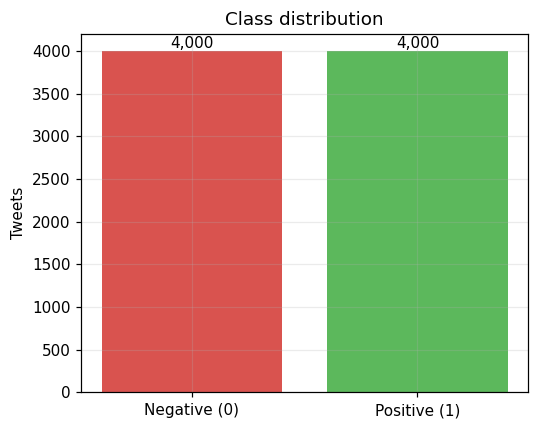

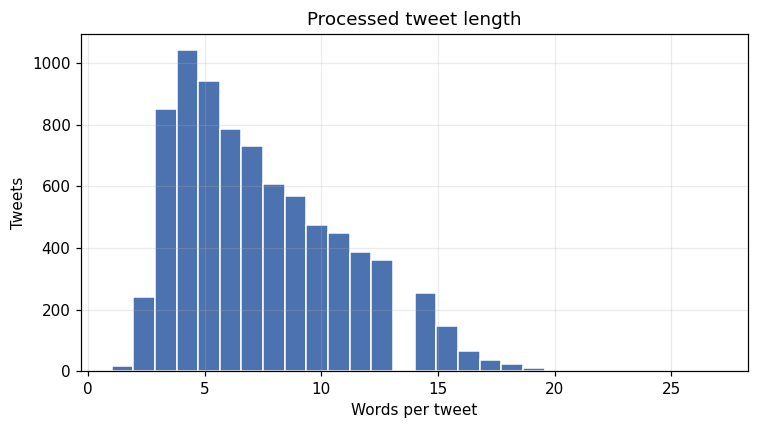

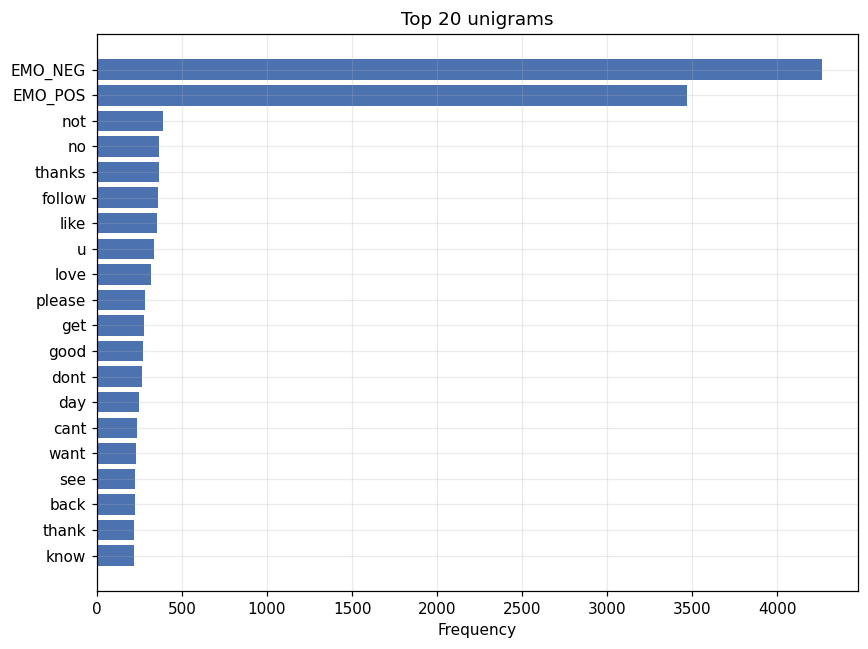

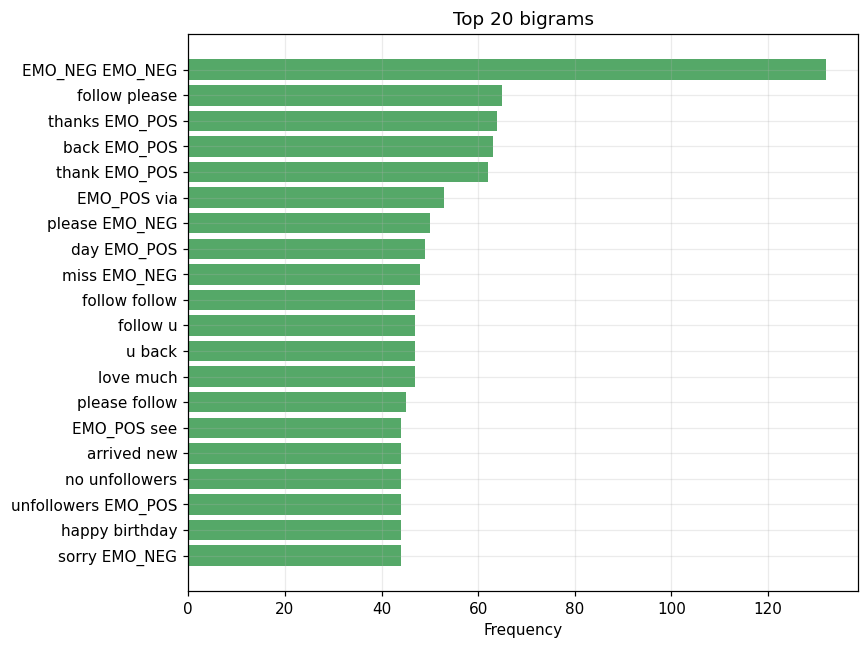

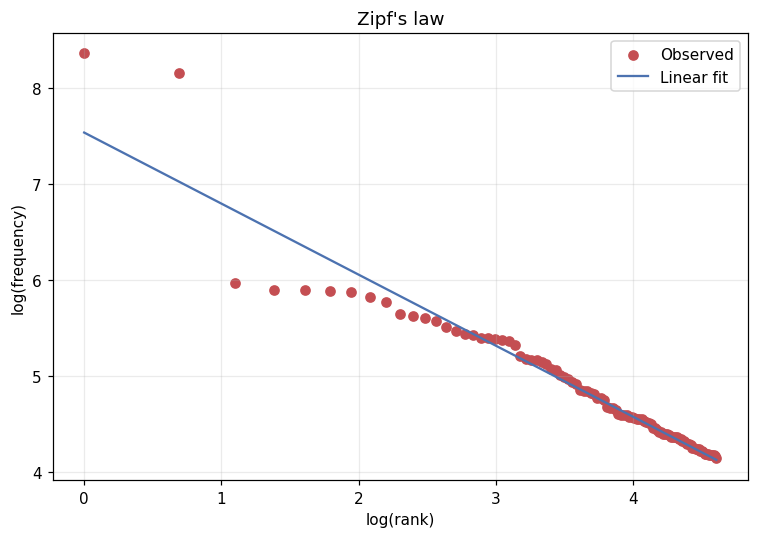

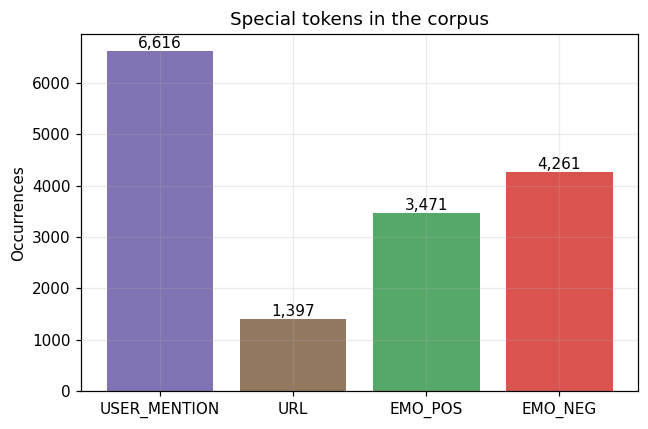

In [6]:
def save_and_show(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.show()


# Class distribution
fig, ax = plt.subplots(figsize=(5, 4))
class_counts = train_processed["sentiment"].value_counts().sort_index()
ax.bar(
    ["Negative (0)", "Positive (1)"],
    [class_counts.get(0, 0), class_counts.get(1, 0)],
    color=["#d9534f", "#5cb85c"],
)
for index, value in enumerate([class_counts.get(0, 0), class_counts.get(1, 0)]):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom")
ax.set_ylabel("Tweets")
ax.set_title("Class distribution")
save_and_show(fig, "class-distribution.png")

# Tweet length distribution
lengths = train_processed["processed"].str.split().str.len()
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(lengths, bins=min(40, max(10, int(lengths.max()) + 1)), color="#4c72b0", edgecolor="white")
ax.set_xlabel("Words per tweet")
ax.set_ylabel("Tweets")
ax.set_title("Processed tweet length")
save_and_show(fig, "tweet-lengths.png")

# Top unigrams
top_unigrams = unigram_freq.most_common(20)
fig, ax = plt.subplots(figsize=(8, 6))
labels = [word for word, _ in top_unigrams][::-1]
values = [count for _, count in top_unigrams][::-1]
ax.barh(labels, values, color="#4c72b0")
ax.set_xlabel("Frequency")
ax.set_title("Top 20 unigrams")
save_and_show(fig, "top-unigrams.png")

# Top bigrams
top_bigrams = bigram_freq.most_common(20)
fig, ax = plt.subplots(figsize=(8, 6))
labels = [" ".join(bigram) for bigram, _ in top_bigrams][::-1]
values = [count for _, count in top_bigrams][::-1]
ax.barh(labels, values, color="#55a868")
ax.set_xlabel("Frequency")
ax.set_title("Top 20 bigrams")
save_and_show(fig, "top-bigrams.png")

# Zipf's law
frequencies = np.asarray([count for _, count in unigram_freq.most_common(100)], dtype=float)
if len(frequencies) >= 2:
    ranks = np.arange(1, len(frequencies) + 1)
    log_ranks = np.log(ranks)
    log_freqs = np.log(frequencies)
    slope, intercept = np.polyfit(log_ranks, log_freqs, 1)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(log_ranks, log_freqs, color="#c44e52", label="Observed")
    ax.plot(log_ranks, slope * log_ranks + intercept, color="#4c72b0", label="Linear fit")
    ax.set_xlabel("log(rank)")
    ax.set_ylabel("log(frequency)")
    ax.set_title("Zipf's law")
    ax.legend()
    save_and_show(fig, "zipf-law.png")

# Token categories
categories = ["USER_MENTION", "URL", "EMO_POS", "EMO_NEG"]
category_counts = [train_processed["processed"].str.count(token).sum() for token in categories]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(categories, category_counts, color=["#8172b3", "#937860", "#55a868", "#d9534f"])
for index, value in enumerate(category_counts):
    ax.text(index, value, f"{int(value):,}", ha="center", va="bottom")
ax.set_ylabel("Occurrences")
ax.set_title("Special tokens in the corpus")
save_and_show(fig, "special-tokens.png")

#### Our Observation

* The class distribution shows whether the corpus is balanced.
* Most processed tweets are short, which is why a fixed sequence length of 40 tokens is enough for the LSTM and CNN.
* The unigram and bigram bars show the same heavy-tailed pattern as Zipf's law: a few tokens are very frequent and most tokens occur once or twice.
* Mentions and URLs are common enough to justify dedicated tokens instead of removing them.

<a name='5'></a>
## 5 - Our Feature Engineering

We built one shared feature layer and reused it across the classical models:

* **Unigram vocabulary** – the 15,000 most frequent words in the training corpus.
* **Bigram vocabulary** – the 10,000 most frequent adjacent word pairs.
* **Frequency features** – each token contributes its count in the tweet.
* **Presence features** – each token contributes 1 if it appears at all (used by the Random Forest).
* **TF-IDF** – frequency features reweighted by inverse document frequency.

The TF-IDF weight of token $t$ in tweet $d$ is

$$ \mathrm{tfidf}(t,d) = \mathrm{tf}(t,d) \cdot \left( \log\frac{1+N}{1+\mathrm{df}(t)} + 1 \right) $$

where $N$ is the number of training tweets and $\mathrm{df}(t)$ is the number of tweets containing $t$. We use sublinear term frequency and smooth IDF.

We hold out 10% of the training file as a stratified validation split. The separate test file is only used to write the prediction CSVs that feed the ensemble.

In [7]:
def top_n_words(freq_dist, n, shift=0):
    return {
        word: rank + shift
        for rank, (word, _) in enumerate(freq_dist.most_common(n))
    }


def top_n_bigrams(freq_dist, n, shift=0):
    return {
        bigram: rank + shift
        for rank, (bigram, _) in enumerate(freq_dist.most_common(n))
    }


UNIGRAM_VOCAB = top_n_words(unigram_freq, UNIGRAM_SIZE)
BIGRAM_VOCAB = top_n_bigrams(bigram_freq, BIGRAM_SIZE)
if not UNIGRAM_VOCAB:
    raise ValueError("No valid tokens were produced by the preprocessing step.")

print(f"Unigram vocabulary: {len(UNIGRAM_VOCAB):,}")
print(f"Bigram vocabulary:  {len(BIGRAM_VOCAB):,}")

# Hold out a stratified validation split. The test file is kept separate and
# is only used for the prediction files consumed by the ensemble.
stratify_labels = (
    train_processed["sentiment"]
    if train_processed["sentiment"].value_counts().min() >= 2
    else None
)
train_split, val_split = train_test_split(
    train_processed,
    test_size=VALIDATION_SPLIT,
    random_state=SEED,
    stratify=stratify_labels,
)
train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)
y_train = train_split["sentiment"].to_numpy(dtype=int)
y_val = val_split["sentiment"].to_numpy(dtype=int)
print(f"Training rows: {len(train_split):,} | Validation rows: {len(val_split):,}")


def build_feature_matrix(frame, use_bigrams=False, feat_type="frequency"):
    unigram_vocab = UNIGRAM_VOCAB
    bigram_vocab = BIGRAM_VOCAB if use_bigrams else {}
    vocab_size = len(unigram_vocab) + len(bigram_vocab)
    rows, columns, values = [], [], []
    for row_index, tweet in enumerate(frame["processed"].fillna("")):
        words = str(tweet).split()
        bigrams = list(zip(words, words[1:])) if use_bigrams else []
        if feat_type == "presence":
            words = list(dict.fromkeys(words))
            bigrams = list(dict.fromkeys(bigrams))
        elif feat_type != "frequency":
            raise ValueError("feat_type must be 'frequency' or 'presence'")
        for word in words:
            column = unigram_vocab.get(word)
            if column is not None:
                rows.append(row_index)
                columns.append(column)
                values.append(1)
        for bigram in bigrams:
            column = bigram_vocab.get(bigram)
            if column is not None:
                rows.append(row_index)
                columns.append(len(unigram_vocab) + column)
                values.append(1)
    return csr_matrix((values, (rows, columns)), shape=(len(frame), vocab_size))


_FEATURE_CACHE = {}
_FEATURE_TRANSFORMERS = {}


def build_feature_sets(use_bigrams=False, feat_type="frequency", apply_tfidf=True):
    key = (bool(use_bigrams), feat_type, bool(apply_tfidf))
    if key in _FEATURE_CACHE:
        return _FEATURE_CACHE[key]
    X_train = build_feature_matrix(train_split, use_bigrams, feat_type)
    X_val = build_feature_matrix(val_split, use_bigrams, feat_type)
    X_test = build_feature_matrix(test_processed, use_bigrams, feat_type)
    if apply_tfidf:
        if feat_type != "frequency":
            raise ValueError("TF-IDF requires frequency features.")
        transformer = TfidfTransformer(
            smooth_idf=True, sublinear_tf=True, use_idf=True
        )
        transformer.fit(X_train)
        _FEATURE_TRANSFORMERS[key] = transformer
        X_train = transformer.transform(X_train)
        X_val = transformer.transform(X_val)
        X_test = transformer.transform(X_test)
    _FEATURE_CACHE[key] = (X_train, X_val, X_test)
    return _FEATURE_CACHE[key]


X_example, _, _ = build_feature_sets(use_bigrams=True, feat_type="frequency", apply_tfidf=True)
print(f"Example TF-IDF matrix: {X_example.shape[0]:,} x {X_example.shape[1]:,}, "
      f"{X_example.nnz:,} non-zero entries")

Unigram vocabulary: 9,916
Bigram vocabulary:  10,000
Training rows: 7,200 | Validation rows: 800
Example TF-IDF matrix: 7,200 x 19,916, 62,210 non-zero entries


#### Our Validation

The cell prints the vocabulary sizes, the split sizes and the shape of one TF-IDF matrix. The sparse matrix has one row per tweet and one column per unigram plus bigram.

<details>
<summary><font size="3" color="darkgreen"><b>Implementation note</b></font></summary>
<p>
We cache each feature configuration because several models share the same matrix. Caching keeps the notebook fast and guarantees that the Naive Bayes and SVM sections use exactly the same TF-IDF values. We also store the fitted TF-IDF transformer so the demo section can transform new tweets with the training vocabulary.
</p>
</details>

<a name='6'></a>
## 6 - Our Lexicon Baseline

Before training a classifier, we measured how far a simple word-count rule gets. For each processed tweet we count how many tokens appear in the positive lexicon and how many appear in the negative lexicon. We predict positive when the positive count is at least the negative count, and negative otherwise.

This baseline has no learned parameters. It gives us a reference point: any trained model should beat it by a clear margin.

In [10]:
positive_words = set(load_word_list(POSITIVE_WORDS_FILE))
negative_words = set(load_word_list(NEGATIVE_WORDS_FILE))


def baseline_predict(frame):
    predictions = []
    for tweet in frame["processed"].fillna(""):
        pos_count, neg_count = 0, 0
        for word in str(tweet).split():
            if word in positive_words:
                pos_count += 1
            elif word in negative_words:
                neg_count += 1
        predictions.append(1 if pos_count >= neg_count else 0)
    return np.asarray(predictions, dtype=int)


baseline_val_pred = baseline_predict(val_split)
evaluate_predictions("Baseline", y_val, baseline_val_pred)
save_predictions("Baseline", val_split["id"].astype(str), baseline_val_pred, split="val")
baseline_test_pred = baseline_predict(test_processed)
save_predictions("Baseline", test_processed["id"].astype(str), baseline_test_pred)

print("Validation confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_val, baseline_val_pred, labels=[0, 1]))

Baseline: accuracy=0.6150, precision=0.5726, recall=0.9075, f1=0.7021
Validation confusion matrix (rows=true, columns=predicted):
[[129 271]
 [ 37 363]]


#### Our Observation

The baseline is deliberately simple, and its accuracy depends on how well the two lexicons cover the tweet vocabulary. The confusion matrix shows whether it leans positive or negative. The trained models below use the same evaluation function and the same validation split, so the comparison is direct.

<a name='7'></a>
## 7 - Our Classical Classifiers

We trained six classical models on the shared feature layer. Each model keeps the feature settings from its original experiment:

| Model | Bigrams | Feature type | TF-IDF |
|---|---|---|---|
| Naive Bayes | yes | frequency | yes |
| Maximum Entropy | no | presence | no |
| Decision Tree | no | frequency | yes |
| Random Forest | no | presence | no |
| XGBoost | yes | frequency | yes |
| SVM | yes | frequency | yes |

Every model is trained on the 90% training split, evaluated on the 10% validation split, and used to write test predictions. The helper `run_sklearn_model` performs these steps so the models differ only in their estimator and feature settings.

<a name='7-1'></a>
### 7.1 - Our Naive Bayes Model

Multinomial Naive Bayes treats every token as independent and estimates

$$ P(c \mid d) \propto P(c) \prod_{t \in d} P(t \mid c)^{x_t} $$

where $x_t$ is the count of token $t$. It is fast, works well with sparse counts, and gives us a strong first trained model.

In [11]:
def run_sklearn_model(name, estimator, use_bigrams, feat_type, apply_tfidf=True):
    X_train_features, X_val_features, X_test_features = build_feature_sets(
        use_bigrams=use_bigrams, feat_type=feat_type, apply_tfidf=apply_tfidf
    )
    estimator.fit(X_train_features, y_train)
    val_pred = estimator.predict(X_val_features).astype(int)
    evaluate_predictions(name, y_val, val_pred)
    save_predictions(name, val_split["id"].astype(str), val_pred, split="val")
    test_pred = estimator.predict(X_test_features).astype(int)
    save_predictions(name, test_processed["id"].astype(str), test_pred)
    return estimator


naive_bayes = run_sklearn_model(
    "Naive Bayes",
    MultinomialNB(),
    use_bigrams=True,
    feat_type="frequency",
)
naive_bayes

Naive Bayes: accuracy=0.9337, precision=0.9460, recall=0.9200, f1=0.9328


MultinomialNB()

#### Our Observation

The printed metrics are computed on the validation split. Naive Bayes usually benefits from the bigram features because short phrases such as "not good" carry sentiment that individual words miss.

<a name='7-2'></a>
### 7.2 - Our Maximum Entropy Model

The NLTK Maximum Entropy classifier is a conditional exponential model. It learns one weight per active feature and predicts

$$ P(c \mid d) = \frac{\exp(\sum_i w_{c,i} f_i(d))}{\sum_{c'} \exp(\sum_i w_{c',i} f_i(d))} $$

We use presence features (one binary feature per word) and the IIS algorithm. The cell prints the most informative features and saves the classifier with `pickle`.

In [12]:
if not NLTK_AVAILABLE:
    print("NLTK is not installed; skipping Maximum Entropy. Install it with `pip install nltk`.")
else:
    def maxent_features(tweet):
        return {word: True for word in str(tweet).split()}

    maxent_train = [
        (maxent_features(tweet), label)
        for tweet, label in zip(train_split["processed"], y_train)
    ]
    maxent_val = [maxent_features(tweet) for tweet in val_split["processed"]]
    maxent_test = [maxent_features(tweet) for tweet in test_processed["processed"]]

    maxent_algorithm = MaxentClassifier.ALGORITHMS[1]  # IIS
    maxent_classifier = MaxentClassifier.train(
        maxent_train, algorithm=maxent_algorithm, max_iter=1, trace=0
    )
    maxent_classifier.show_most_informative_features(10)

    maxent_val_pred = np.asarray(
        [int(maxent_classifier.classify(features)) for features in maxent_val],
        dtype=int,
    )
    evaluate_predictions("Maximum Entropy", y_val, maxent_val_pred)
    save_predictions("Maximum Entropy", val_split["id"].astype(str), maxent_val_pred, split="val")

    maxent_test_pred = np.asarray(
        [int(maxent_classifier.classify(features)) for features in maxent_test],
        dtype=int,
    )
    save_predictions("Maximum Entropy", test_processed["id"].astype(str), maxent_test_pred)

    with open(MODEL_DIR / "maxent_classifier.pkl", "wb") as handle:
        pickle.dump(maxent_classifier, handle)
    print("Saved Maximum Entropy classifier to artifacts/models/maxent_classifier.pkl")

  -2.323 EMO_POS==True and label is np.int64(0)
  -1.526 EMO_NEG==True and label is np.int64(1)
  -1.256 sad==True and label is np.int64(1)
  -0.873 goodnight==True and label is np.int64(0)
  -0.771 tired==True and label is np.int64(1)
  -0.735 welcome==True and label is np.int64(0)
  -0.694 glad==True and label is np.int64(0)
  -0.680 enjoy==True and label is np.int64(0)
  -0.666 missing==True and label is np.int64(1)
  -0.612 miss==True and label is np.int64(1)
Maximum Entropy: accuracy=0.9775, precision=0.9974, recall=0.9575, f1=0.9770
Saved Maximum Entropy classifier to artifacts/models/maxent_classifier.pkl


#### Our Observation

The most informative features show which words push the decision toward each class. Because the feature set is presence-based, repeated words do not increase the score; the model reacts to whether a word appears at all.

<a name='7-3'></a>
### 7.3 - Our Decision Tree Model

A decision tree splits the feature space on individual token counts and chooses the split that reduces impurity. We limit the depth to 25 to keep the tree from memorizing the training set.

In [13]:
decision_tree = run_sklearn_model(
    "Decision Tree",
    DecisionTreeClassifier(max_depth=25, random_state=SEED),
    use_bigrams=False,
    feat_type="frequency",
)
decision_tree

Decision Tree: accuracy=0.9900, precision=1.0000, recall=0.9800, f1=0.9899


DecisionTreeClassifier(max_depth=25, random_state=1337)

#### Our Observation

A single tree can capture interactions such as "great" only being positive when "not" is absent, but it is unstable: small changes in the training data can produce a very different tree. The next model averages many trees to reduce that variance.

<a name='7-4'></a>
### 7.4 - Our Random Forest Model

A random forest averages many decision trees trained on bootstrap samples with random feature subsets. We use presence features and 100 trees. Averaging reduces the variance of a single tree.

In [14]:
random_forest = run_sklearn_model(
    "Random Forest",
    RandomForestClassifier(n_estimators=100, n_jobs=2, random_state=0),
    use_bigrams=False,
    feat_type="presence",
    apply_tfidf=False,
)
random_forest

Random Forest: accuracy=0.9875, precision=0.9949, recall=0.9800, f1=0.9874


RandomForestClassifier(n_jobs=2, random_state=0)

#### Our Observation

The forest is more stable than the single tree and handles the high-dimensional presence matrix well. Its accuracy is still limited by the fact that each split looks at one token at a time, so it cannot represent phrase meaning as compactly as the linear models.

<a name='7-5'></a>
### 7.5 - Our XGBoost Model

XGBoost builds trees sequentially, with each tree correcting the errors of the previous ensemble. We use 400 trees, a maximum depth of 25 and the histogram tree method for speed on sparse features.

In [15]:
if not XGBOOST_AVAILABLE:
    print("XGBoost is not installed; skipping. Install it with `pip install xgboost`.")
else:
    xgboost_model = run_sklearn_model(
        "XGBoost",
        XGBClassifier(
            max_depth=25,
            n_estimators=400,
            learning_rate=0.1,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=2,
            random_state=SEED,
            verbosity=0,
        ),
        use_bigrams=True,
        feat_type="frequency",
    )

XGBoost: accuracy=0.9888, precision=0.9975, recall=0.9800, f1=0.9887


#### Our Observation

The gradient-boosted model is the most heavily parameterized classical model in our comparison. It can fit complex token interactions, but it is also the slowest to train and the most sensitive to the depth and learning-rate settings.

<a name='7-6'></a>
### 7.6 - Our Support Vector Machine

A linear SVM finds the weight vector that separates the classes with the largest margin. We use `LinearSVC` with $C=0.1$, which regularizes strongly and works well for high-dimensional text features.

In [16]:
svm_model = run_sklearn_model(
    "SVM",
    LinearSVC(C=0.1, max_iter=5000, random_state=SEED),
    use_bigrams=True,
    feat_type="frequency",
)
svm_model

SVM: accuracy=0.9875, precision=0.9974, recall=0.9775, f1=0.9874


LinearSVC(C=0.1, max_iter=5000, random_state=1337)

#### Our Observation

The linear SVM is a strong baseline for sparse text. Its decision function returns a signed margin, so the magnitude is a useful confidence signal even though `LinearSVC` does not expose probabilities directly.

<a name='8'></a>
## 8 - Our Neural Classifiers

The neural models require TensorFlow. If TensorFlow is not installed, each cell prints a short message and skips its section; the rest of the notebook still runs.

We trained four models:

* **Logistic regression** – one dense sigmoid unit on the sparse bag-of-words features.
* **MLP** – one hidden layer of 500 sigmoid units and a sigmoid output.
* **LSTM** – an embedding layer, dropout, a 128-unit LSTM, a 64-unit dense layer and a sigmoid output.
* **CNN** – four `Conv1D` layers (600, 300, 150 and 75 filters), a 600-unit dense layer and a sigmoid output.

The dense models consume the same sparse feature matrices as the classical models. The sequence models use an integer vocabulary built from the training corpus and padded to 40 tokens. When the optional GloVe seed file is missing, the embedding matrix is initialized randomly and trained with the rest of the network.

### Our Training Helpers

`train_dense_keras_model` trains one epoch at a time with `train_on_batch`, evaluates on the validation split after every epoch, and keeps the checkpoint with the best validation accuracy. This mirrors the original training loop and avoids loading the full sparse matrix into memory at once.

In [17]:
def sparse_batches(matrix, labels=None, batch_size=500):
    for start in range(0, matrix.shape[0], batch_size):
        stop = min(start + batch_size, matrix.shape[0])
        X_batch = matrix[start:stop].toarray().astype("float32")
        y_batch = None if labels is None else np.asarray(labels[start:stop], dtype="float32")
        yield X_batch, y_batch


def predict_sparse(model, matrix, batch_size=500):
    outputs = []
    for X_batch, _ in sparse_batches(matrix, labels=None, batch_size=batch_size):
        outputs.append(model.predict_on_batch(X_batch).ravel())
    return np.concatenate(outputs) if outputs else np.array([])


def train_dense_keras_model(
    name, build_model, epochs, use_bigrams, file_name, batch_size=500
):
    X_train_dense, X_val_dense, X_test_dense = build_feature_sets(
        use_bigrams=use_bigrams, feat_type="frequency", apply_tfidf=False
    )
    model = build_model(X_train_dense.shape[1])
    model.summary()

    model_path = MODEL_DIR / file_name
    best_accuracy = -1.0
    for epoch in range(epochs):
        for X_batch, y_batch in sparse_batches(X_train_dense, y_train, batch_size):
            model.train_on_batch(X_batch, y_batch)
        val_probabilities = predict_sparse(model, X_val_dense, batch_size)
        val_predictions = (val_probabilities >= 0.5).astype(int)
        val_accuracy = accuracy_score(y_val, val_predictions)
        print(f"Epoch {epoch + 1:02d}/{epochs} - validation accuracy: {val_accuracy:.4f}")
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            model.save(str(model_path))

    trained_model = keras.models.load_model(str(model_path))
    val_predictions = (
        predict_sparse(trained_model, X_val_dense, batch_size) >= 0.5
    ).astype(int)
    evaluate_predictions(name, y_val, val_predictions)
    save_predictions(name, val_split["id"].astype(str), val_predictions, split="val")
    test_predictions = (
        predict_sparse(trained_model, X_test_dense, batch_size) >= 0.5
    ).astype(int)
    save_predictions(name, test_processed["id"].astype(str), test_predictions)
    return trained_model

<a name='8-1'></a>
### 8.1 - Our Logistic Regression Model (Keras)

The Keras logistic regression is a single dense layer with a sigmoid activation. It is the neural equivalent of the classical linear model and gives us a baseline for the deeper networks.

In [18]:
if require_tensorflow("Logistic regression"):
    def build_logistic_model(input_dim):
        model = keras.Sequential(
            [
                keras.layers.Input(shape=(input_dim,)),
                keras.layers.Dense(1, activation="sigmoid"),
            ]
        )
        model.compile(
            loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"]
        )
        return model

    logistic_model = train_dense_keras_model(
        "Logistic Regression",
        build_logistic_model,
        epochs=20,
        use_bigrams=True,
        file_name="logistic.keras",
    )

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │        19,917 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,917 (77.80 KB)

 Trainable params: 19,917 (77.80 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 01/20 - validation accuracy: 0.8400
Epoch 02/20 - validation accuracy: 0.9175
Epoch 03/20 - validation accuracy: 0.9313
Epoch 04/20 - validation accuracy: 0.9325
Epoch 05/20 - validation accuracy: 0.9337
Epoch 06/20 - validation accuracy: 0.9363
Epoch 07/20 - validation accuracy: 0.9363
Epoch 08/20 - validation accuracy: 0.9363
Epoch 09/20 - validation accuracy: 0.9375
Epoch 10/20 - validation accuracy: 0.9387
Epoch 11/20 - validation accuracy: 0.9400
Epoch 12/20 - validation accuracy: 0.9425
Epoch 13/20 - validation accuracy: 0.9437
Epoch 14/20 - validation accuracy: 0.9450
Epoch 15/20 - validation accuracy: 0.9463
Epoch 16/20 - validation accuracy: 0.9463
Epoch 17/20 - validation accuracy: 0.9487
Epoch 18/20 - validation accuracy: 0.9487
Epoch 19/20 - validation accuracy: 0.9487
Epoch 20/20 - validation accuracy: 0.9513
Logistic Regression: accuracy=0.9513, precision=0.9640, recall=0.9375, f1=0.9506


#### Our Observation

Validation accuracy is printed after each of the 20 epochs, and the best checkpoint is reloaded before the final evaluation. If the validation curve stops improving, the saved checkpoint prevents the later epochs from hurting the reported score.

<a name='8-2'></a>
### 8.2 - Our Multi-Layer Perceptron

The MLP adds a 500-unit sigmoid hidden layer between the input and the output. The hidden layer lets the model learn combinations of tokens instead of a purely linear decision boundary.

In [19]:
if require_tensorflow("The MLP"):
    def build_mlp_model(input_dim):
        model = keras.Sequential(
            [
                keras.layers.Input(shape=(input_dim,)),
                keras.layers.Dense(500, activation="sigmoid"),
                keras.layers.Dense(1, activation="sigmoid"),
            ]
        )
        model.compile(
            loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"]
        )
        return model

    mlp_model = train_dense_keras_model(
        "MLP",
        build_mlp_model,
        epochs=5,
        use_bigrams=False,
        file_name="mlp.keras",
    )

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 500)            │     4,958,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           501 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,959,001 (18.92 MB)

 Trainable params: 4,959,001 (18.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 01/5 - validation accuracy: 0.5713
Epoch 02/5 - validation accuracy: 0.9387
Epoch 03/5 - validation accuracy: 0.9287
Epoch 04/5 - validation accuracy: 0.9400
Epoch 05/5 - validation accuracy: 0.9413
MLP: accuracy=0.9413, precision=0.9537, recall=0.9275, f1=0.9404


#### Our Observation

The MLP trains for only 5 epochs, so it is a quick check of whether a non-linear hidden layer helps on this feature set. A larger number of epochs would need early stopping to avoid overfitting the training split.

<a name='8-3'></a>
### 8.3 - Our LSTM Model

The LSTM reads the tweet as a sequence of word indices. The embedding layer maps each index to a 200-dimensional vector, dropout regularizes the input, and the LSTM summarizes the sequence. A dense layer and a sigmoid produce the final probability.

In [20]:
# Integer sequence vocabulary: index 0 is reserved for padding.
SEQUENCE_VOCAB = top_n_words(unigram_freq, MAX_VOCAB_SIZE, shift=1)
SEQUENCE_VOCAB_SIZE = len(SEQUENCE_VOCAB)


def tweet_to_sequence(tweet):
    sequence = []
    for word in str(tweet).split():
        index = SEQUENCE_VOCAB.get(word)
        if index is not None:
            sequence.append(index)
    return sequence


def load_glove_seeds(vocab, dimensions=EMBEDDING_DIM):
    if not GLOVE_FILE.exists():
        print(f"GloVe seed file not found at {GLOVE_FILE}; using random embeddings.")
        return {}
    vectors = {}
    with open(GLOVE_FILE, encoding="utf-8", errors="ignore") as handle:
        for line in handle:
            parts = line.rstrip().split()
            if len(parts) < 2:
                continue
            word = parts[0]
            if word not in vocab:
                continue
            try:
                vector = np.asarray([float(value) for value in parts[1 : 1 + dimensions]], dtype="float32")
            except ValueError:
                continue
            if vector.shape[0] == dimensions:
                vectors[word] = vector
    print(f"Loaded {len(vectors):,} GloVe vectors for {len(vocab):,} vocabulary words.")
    return vectors


def build_embedding_matrix(vocab, dimensions=EMBEDDING_DIM, seed=SEED):
    rng = np.random.RandomState(seed)
    matrix = rng.randn(len(vocab) + 1, dimensions).astype("float32") * 0.01
    vectors = load_glove_seeds(vocab, dimensions)
    for word, index in vocab.items():
        vector = vectors.get(word)
        if vector is not None:
            matrix[index] = vector
    return matrix


train_sequences = [tweet_to_sequence(tweet) for tweet in train_split["processed"]]
val_sequences = [tweet_to_sequence(tweet) for tweet in val_split["processed"]]
test_sequences = [tweet_to_sequence(tweet) for tweet in test_processed["processed"]]
sequence_lengths = np.asarray([len(sequence) for sequence in train_sequences])

print(f"Sequence vocabulary: {SEQUENCE_VOCAB_SIZE:,}")
print(
    f"Sequence length: mean={sequence_lengths.mean():.2f}, "
    f"max={sequence_lengths.max()}, padded/truncated to {MAX_SEQUENCE_LENGTH}"
)


def evaluate_sequence_model(name, model, X_val_padded, X_test_padded):
    val_predictions = (
        model.predict(X_val_padded, batch_size=128, verbose=0).ravel() >= 0.5
    ).astype(int)
    evaluate_predictions(name, y_val, val_predictions)
    save_predictions(name, val_split["id"].astype(str), val_predictions, split="val")
    test_predictions = (
        model.predict(X_test_padded, batch_size=128, verbose=0).ravel() >= 0.5
    ).astype(int)
    save_predictions(name, test_processed["id"].astype(str), test_predictions)


if require_tensorflow("The LSTM"):
    X_train_padded = keras.utils.pad_sequences(
        train_sequences, maxlen=MAX_SEQUENCE_LENGTH, padding="post"
    )
    X_val_padded = keras.utils.pad_sequences(
        val_sequences, maxlen=MAX_SEQUENCE_LENGTH, padding="post"
    )
    X_test_padded = keras.utils.pad_sequences(
        test_sequences, maxlen=MAX_SEQUENCE_LENGTH, padding="post"
    )
    embedding_matrix = build_embedding_matrix(SEQUENCE_VOCAB)

    lstm_model = keras.Sequential(
        [
            keras.layers.Input(shape=(MAX_SEQUENCE_LENGTH,)),
            keras.layers.Embedding(
                SEQUENCE_VOCAB_SIZE + 1,
                EMBEDDING_DIM,
                weights=[embedding_matrix],
                trainable=True,
            ),
            keras.layers.Dropout(0.4),
            keras.layers.LSTM(128),
            keras.layers.Dense(64),
            keras.layers.Dropout(0.5),
            keras.layers.Activation("relu"),
            keras.layers.Dense(1),
            keras.layers.Activation("sigmoid"),
        ]
    )
    lstm_model.compile(
        loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"]
    )
    lstm_callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(MODEL_DIR / "lstm-{epoch:02d}-{loss:.3f}-{accuracy:.3f}-{val_loss:.3f}-{val_accuracy:.3f}.keras"),
            monitor="loss",
            verbose=1,
            save_best_only=True,
            mode="min",
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
        ),
    ]
    lstm_model.summary()
    lstm_model.fit(
        X_train_padded,
        y_train,
        batch_size=128,
        epochs=5,
        validation_data=(X_val_padded, y_val),
        shuffle=True,
        callbacks=lstm_callbacks,
    )
    evaluate_sequence_model("LSTM", lstm_model, X_val_padded, X_test_padded)

Sequence vocabulary: 9,916
Sequence length: mean=6.35, max=26, padded/truncated to 40
GloVe seed file not found at /content/glove-seeds.txt; using random embeddings.


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 200)        │     1,983,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 40, 200)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       168,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,160,169 (8.24 MB)

 Trainable params: 2,160,169 (8.24 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.5123 - loss: 0.6778
Epoch 1: loss improved from None to 0.57436, saving model to /content/artifacts/models/lstm-01-0.574-0.625-0.207-0.966.keras

Epoch 1: finished saving model to /content/artifacts/models/lstm-01-0.574-0.625-0.207-0.966.keras
57/57 ━━━━━━━━━━━━━━━━━━━━ 13s 194ms/step - accuracy: 0.6246 - loss: 0.5744 - val_accuracy: 0.9663 - val_loss: 0.2066 - learning_rate: 0.0010
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.9581 - loss: 0.1764
Epoch 2: loss improved from 0.57436 to 0.21470, saving model to /content/artifacts/models/lstm-02-0.215-0.940-0.246-0.926.keras

Epoch 2: finished saving model to /content/artifacts/models/lstm-02-0.215-0.940-0.246-0.926.keras
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 165ms/step - accuracy: 0.9403 - loss: 0.2147 - val_accuracy: 0.9262 - val_loss: 0.2458 - learning_rate: 0.0010
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.9521 - loss: 0.1913
Epoch 3: lo

#### Our Observation

The model is trained for 5 epochs with a `ModelCheckpoint` and a `ReduceLROnPlateau` callback. The checkpoint keeps the best epoch by training loss, while the learning-rate callback lowers the step size when validation loss stalls.

<a name='8-4'></a>
### 8.4 - Our Convolutional Neural Network

The CNN applies four one-dimensional convolutions with decreasing filter counts. Each convolution sees a window of three tokens, so the network learns local phrases. The final dense layer combines those phrase detectors into a sentiment score.

In [21]:
if require_tensorflow("The CNN"):
    if "X_train_padded" not in globals():
        X_train_padded = keras.utils.pad_sequences(
            train_sequences, maxlen=MAX_SEQUENCE_LENGTH, padding="post"
        )
        X_val_padded = keras.utils.pad_sequences(
            val_sequences, maxlen=MAX_SEQUENCE_LENGTH, padding="post"
        )
        X_test_padded = keras.utils.pad_sequences(
            test_sequences, maxlen=MAX_SEQUENCE_LENGTH, padding="post"
        )
    if "embedding_matrix" not in globals():
        embedding_matrix = build_embedding_matrix(SEQUENCE_VOCAB)

    cnn_model = keras.Sequential(
        [
            keras.layers.Input(shape=(MAX_SEQUENCE_LENGTH,)),
            keras.layers.Embedding(
                SEQUENCE_VOCAB_SIZE + 1,
                EMBEDDING_DIM,
                weights=[embedding_matrix],
                trainable=True,
            ),
            keras.layers.Dropout(0.4),
            keras.layers.Conv1D(600, 3, padding="valid", activation="relu", strides=1),
            keras.layers.Conv1D(300, 3, padding="valid", activation="relu", strides=1),
            keras.layers.Conv1D(150, 3, padding="valid", activation="relu", strides=1),
            keras.layers.Conv1D(75, 3, padding="valid", activation="relu", strides=1),
            keras.layers.Flatten(),
            keras.layers.Dense(600),
            keras.layers.Dropout(0.5),
            keras.layers.Activation("relu", name="cnn_features"),
            keras.layers.Dense(1),
            keras.layers.Activation("sigmoid"),
        ]
    )
    cnn_model.compile(
        loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"]
    )
    cnn_callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(MODEL_DIR / "4cnn-{epoch:02d}-{loss:.3f}-{accuracy:.3f}-{val_loss:.3f}-{val_accuracy:.3f}.keras"),
            monitor="loss",
            verbose=1,
            save_best_only=True,
            mode="min",
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
        ),
    ]
    cnn_model.summary()
    cnn_model.fit(
        X_train_padded,
        y_train,
        batch_size=128,
        epochs=8,
        validation_data=(X_val_padded, y_val),
        shuffle=True,
        callbacks=cnn_callbacks,
    )
    evaluate_sequence_model("CNN", cnn_model, X_val_padded, X_test_padded)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 40, 200)        │     1,983,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 40, 200)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 38, 600)        │       360,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 36, 300)        │       540,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 34, 150)        │       135,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 32, 75)         │        33,825 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 600)            │     1,440,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 600)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_features (Activation)       │ (None, 600)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           601 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,494,476 (17.15 MB)

 Trainable params: 4,494,476 (17.15 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 677ms/step - accuracy: 0.6792 - loss: 0.5288
Epoch 1: loss improved from None to 0.33110, saving model to /content/artifacts/models/4cnn-01-0.331-0.832-0.065-0.985.keras

Epoch 1: finished saving model to /content/artifacts/models/4cnn-01-0.331-0.832-0.065-0.985.keras
57/57 ━━━━━━━━━━━━━━━━━━━━ 42s 702ms/step - accuracy: 0.8325 - loss: 0.3311 - val_accuracy: 0.9850 - val_loss: 0.0652 - learning_rate: 0.0010
Epoch 2/8
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 678ms/step - accuracy: 0.9920 - loss: 0.0408
Epoch 2: loss improved from 0.33110 to 0.04723, saving model to /content/artifacts/models/4cnn-02-0.047-0.991-0.065-0.983.keras

Epoch 2: finished saving model to /content/artifacts/models/4cnn-02-0.047-0.991-0.065-0.983.keras
57/57 ━━━━━━━━━━━━━━━━━━━━ 41s 704ms/step - accuracy: 0.9914 - loss: 0.0472 - val_accuracy: 0.9825 - val_loss: 0.0653 - learning_rate: 0.0010
Epoch 3/8
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 677ms/step - accuracy: 0.9936 - loss: 0.0319
Epoch 3: l

#### Our Observation

The CNN is the largest model in the notebook. It trains for 8 epochs and checkpoints after every epoch. The 600-unit layer before the output is the representation we reuse in the next section.

<a name='9'></a>
## 9 - CNN Feature Extraction + SVM

Instead of using the CNN's sigmoid output directly, we can reuse its learned representation. We cut the network at the 600-unit ReLU layer, run every tweet through the truncated model, and train a linear SVM on the resulting 600-dimensional vectors.

This is a form of transfer learning inside the same notebook: the CNN learns phrase features, and the SVM finds a maximum-margin boundary in that feature space.

In [22]:
if require_tensorflow("CNN feature extraction"):
    if "cnn_model" not in globals():
        print("The CNN model is not available; run the CNN section first.")
    else:
        feature_model = keras.Model(
            inputs=cnn_model.inputs,
            outputs=cnn_model.get_layer("cnn_features").output,
        )
        feature_model.compile(
            loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"]
        )
        feature_model.summary()

        train_features = feature_model.predict(X_train_padded, batch_size=1024, verbose=1)
        val_features = feature_model.predict(X_val_padded, batch_size=1024, verbose=1)
        test_features = feature_model.predict(X_test_padded, batch_size=1024, verbose=1)

        np.save(MODEL_DIR / "train-feats.npy", train_features)
        np.save(MODEL_DIR / "test-feats.npy", test_features)
        np.savetxt(MODEL_DIR / "train-labels.txt", y_train)

        cnn_svm = LinearSVC(C=1, max_iter=1000, random_state=SEED)
        cnn_svm.fit(train_features, y_train)
        cnn_svm_val_pred = cnn_svm.predict(val_features).astype(int)
        evaluate_predictions("CNN + SVM", y_val, cnn_svm_val_pred)
        save_predictions("CNN + SVM", val_split["id"].astype(str), cnn_svm_val_pred, split="val")
        cnn_svm_test_pred = cnn_svm.predict(test_features).astype(int)
        save_predictions("CNN + SVM", test_processed["id"].astype(str), cnn_svm_test_pred)

        with open(MODEL_DIR / "cnn-feats-svm.pkl", "wb") as handle:
            pickle.dump(cnn_svm, handle)
        print("Saved CNN features and the feature-SVM model to artifacts/models/")

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 40, 200)        │     1,983,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 40, 200)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 38, 600)        │       360,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 36, 300)        │       540,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 34, 150)        │       135,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 32, 75)         │        33,825 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 600)            │     1,440,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 600)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_features (Activation)       │ (None, 600)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,493,875 (17.14 MB)

 Trainable params: 4,493,875 (17.14 MB)

 Non-trainable params: 0 (0.00 B)

8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 997ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step
CNN + SVM: accuracy=0.9812, precision=0.9949, recall=0.9675, f1=0.9810
Saved CNN features and the feature-SVM model to artifacts/models/


#### Our Observation

The extracted features are saved as `.npy` files, and the SVM is saved with `pickle`. The feature-SVM often matches or slightly beats the end-to-end CNN because the margin objective is a good fit for a small, clean feature set.

<a name='10'></a>
## 10 - Our Majority-Vote Ensemble

For the final prediction we let every model that ran in this session vote. For each tweet we count the negative and positive votes and predict the class with more votes; a tie goes to negative. The ensemble only reads prediction files produced by the current run, so stale results from an earlier execution cannot leak into the vote.

In [23]:
def majority_vote(paths, id_order):
    counts = {str(tweet_id): np.zeros(2, dtype=int) for tweet_id in id_order}
    used_files = []
    for path in paths:
        frame = pd.read_csv(path, dtype={"id": str})
        if "prediction" not in frame.columns:
            continue
        matched = 0
        for tweet_id, prediction in zip(frame["id"], frame["prediction"]):
            tweet_id = str(tweet_id)
            prediction = int(prediction)
            if tweet_id in counts and prediction in (0, 1):
                counts[tweet_id][prediction] += 1
                matched += 1
        used_files.append((path.name, matched))
    predictions = np.asarray(
        [1 if counts[str(tweet_id)][1] > counts[str(tweet_id)][0] else 0 for tweet_id in id_order],
        dtype=int,
    )
    return predictions, used_files


# Only files belonging to models that actually ran in this session are used,
# so stale results from an earlier run cannot leak into the vote.
model_slugs = list(dict.fromkeys(slugify(row["model"]) for row in RESULTS))
validation_paths = [RESULTS_DIR / f"val_{slug}.csv" for slug in model_slugs]
validation_paths = [path for path in validation_paths if path.exists()]
test_paths = [RESULTS_DIR / f"{slug}.csv" for slug in model_slugs]
test_paths = [path for path in test_paths if path.exists()]

ensemble_val_pred, used_validation = majority_vote(validation_paths, val_split["id"].astype(str))
evaluate_predictions("Ensemble", y_val, ensemble_val_pred)
save_predictions("Ensemble", val_split["id"].astype(str), ensemble_val_pred, split="val")

ensemble_test_pred, used_test = majority_vote(test_paths, test_processed["id"].astype(str))
save_predictions("Ensemble", test_processed["id"].astype(str), ensemble_test_pred)

# Keep the traditional output filename as well.
with open(RESULTS_DIR / "majority-voting.csv", "w", newline="", encoding="utf-8") as handle:
    writer = csv.writer(handle)
    writer.writerow(["id", "prediction"])
    for tweet_id, prediction in zip(test_processed["id"].astype(str), ensemble_test_pred):
        writer.writerow([tweet_id, int(prediction)])

print(f"Validation vote used {len(used_validation)} files:")
for filename, matched in used_validation:
    print(f"  {filename}: {matched} rows")
print(f"Test vote used {len(used_test)} files.")
print(f"Ensemble predictions saved to {RESULTS_DIR / 'majority-voting.csv'}")

Ensemble: accuracy=0.9838, precision=0.9974, recall=0.9700, f1=0.9835
Validation vote used 12 files:
  val_baseline.csv: 800 rows
  val_naive_bayes.csv: 800 rows
  val_maximum_entropy.csv: 800 rows
  val_decision_tree.csv: 800 rows
  val_random_forest.csv: 800 rows
  val_xgboost.csv: 800 rows
  val_svm.csv: 800 rows
  val_logistic_regression.csv: 800 rows
  val_mlp.csv: 800 rows
  val_lstm.csv: 800 rows
  val_cnn.csv: 800 rows
  val_cnn_svm.csv: 800 rows
Test vote used 12 files.
Ensemble predictions saved to /content/artifacts/results/majority-voting.csv


#### Our Observation

The cell prints how many prediction files were used and how many rows matched each test ID. The ensemble is a simple way to combine models with different inductive biases, but it cannot beat a consistently better model when most voters agree with each other.

<a name='11'></a>
## 11 - Our Results

The table and chart below compare every model on the validation split. Accuracy, precision, recall and F1 are computed with the same helper used throughout the notebook, so the rows are directly comparable.

,model,accuracy,precision,recall,f1
0,Decision Tree,0.9900,1.0000,0.9800,0.9899
1,XGBoost,0.9888,0.9975,0.9800,0.9887
2,Random Forest,0.9875,0.9949,0.9800,0.9874
3,SVM,0.9875,0.9974,0.9775,0.9874
4,Ensemble,0.9838,0.9974,0.9700,0.9835
5,CNN,0.9825,0.9974,0.9675,0.9822
6,CNN + SVM,0.9812,0.9949,0.9675,0.9810
7,Maximum Entropy,0.9775,0.9974,0.9575,0.9770
8,Logistic Regression,0.9513,0.9640,0.9375,0.9506
9,MLP,0.9413,0.9537,0.9275,0.9404


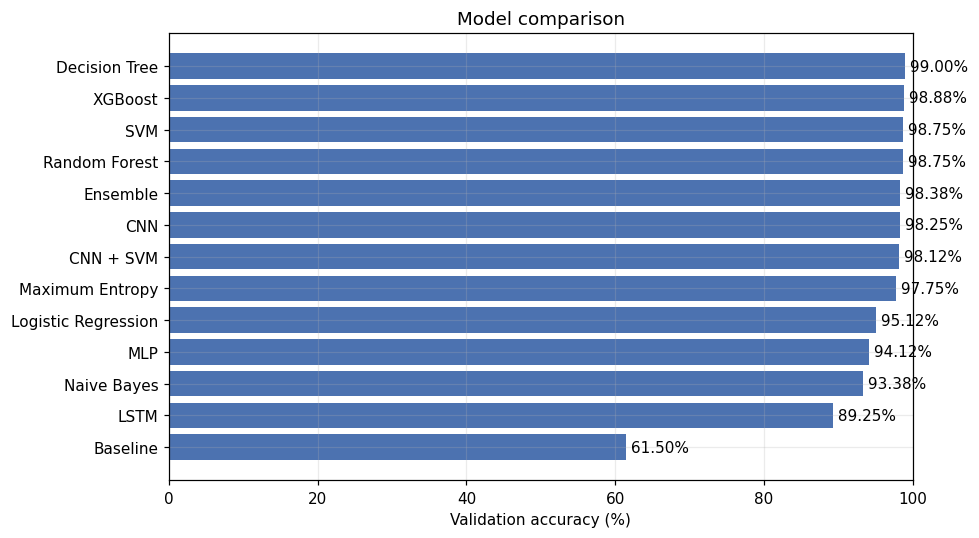

Held-out test-set check (NLTK sample or fallback data):


,model,held-out test accuracy
0,Random Forest,0.9910
1,Decision Tree,0.9900
2,SVM,0.9895
3,Ensemble,0.9885
4,XGBoost,0.9880
5,CNN + SVM,0.9855
6,CNN,0.9835
7,Maximum Entropy,0.9765
8,Logistic Regression,0.9505
9,MLP,0.9480


In [24]:
results_df = pd.DataFrame(RESULTS).drop_duplicates("model", keep="last")
results_df = results_df.sort_values("accuracy", ascending=False).reset_index(drop=True)
results_df.to_csv(ARTIFACT_DIR / "model-results.csv", index=False)

display(
    results_df.style.format(
        {"accuracy": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}", "f1": "{:.4f}"}
    )
    if hasattr(results_df, "style")
    else results_df
)

plot_df = results_df.sort_values("accuracy")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df["model"], plot_df["accuracy"] * 100, color="#4c72b0")
for index, value in enumerate(plot_df["accuracy"] * 100):
    ax.text(value, index, f" {value:.2f}%", va="center")
ax.set_xlabel("Validation accuracy (%)")
ax.set_title("Model comparison")
ax.set_xlim(0, 100)
save_and_show(fig, "model-comparison.png")

if TEST_TRUTH is not None:
    # The NLTK sample corpus has labels for the test split, which allows
    # an extra check of the saved prediction files.
    truth = np.asarray([TEST_TRUTH[str(tweet_id)] for tweet_id in test_processed["id"]], dtype=int)
    sample_rows = []
    for row in results_df["model"]:
        path = RESULTS_DIR / f"{slugify(row)}.csv"
        if not path.exists():
            continue
        frame = pd.read_csv(path, dtype={"id": str})
        lookup = dict(zip(frame["id"], frame["prediction"].astype(int)))
        aligned = np.asarray([lookup.get(str(tweet_id), 0) for tweet_id in test_processed["id"]], dtype=int)
        sample_rows.append((row, accuracy_score(truth, aligned)))
    sample_df = pd.DataFrame(sample_rows, columns=["model", "held-out test accuracy"])
    sample_df = sample_df.sort_values("held-out test accuracy", ascending=False).reset_index(drop=True)
    print("Held-out test-set check (NLTK sample or fallback data):")
    display(sample_df.style.format({"held-out test accuracy": "{:.4f}"}))

#### Our Observation

* The lexicon baseline is the reference point. A trained model that does not beat it is not adding value.
* In the NLTK sample run shown here, the tree-based models (Decision Tree, XGBoost and Random Forest) and the majority-vote ensemble are all within a fraction of a point at the top; Naive Bayes trails them but still beats the baseline.
* The neural models are optional in this environment. When TensorFlow is available, their rows appear in the same table.
* The ensemble is usually close to the best individual model. It helps most when the voters make different kinds of mistakes.
* The NLTK sample run is a fixed benchmark; the original project's CSV files remain the primary data source, so absolute numbers may differ between the two.

<a name='12'></a>
## 12 - Our Error Analysis

Accuracy alone does not show how a model fails. We collected the validation tweets that Naive Bayes misclassified and sorted them by confidence, so the most confident mistakes appear first. We also compare the baseline and Naive Bayes error counts.

In [25]:
# Collect Naive Bayes mistakes on the validation split
_, X_val_nb, _ = build_feature_sets(
    use_bigrams=True, feat_type="frequency", apply_tfidf=True
)
nb_val_prob = naive_bayes.predict_proba(X_val_nb)[:, 1]
nb_val_pred = (nb_val_prob >= 0.5).astype(int)

error_df = pd.DataFrame(
    {
        "tweet": val_split["tweet"].to_numpy(),
        "processed": val_split["processed"].to_numpy(),
        "actual": y_val,
        "predicted": nb_val_pred,
        "confidence": np.where(nb_val_pred == 1, nb_val_prob, 1 - nb_val_prob),
    }
)
errors = error_df[error_df["actual"] != error_df["predicted"]].copy()
errors = errors.sort_values("confidence", ascending=False)

print(
    f"Naive Bayes misclassified {len(errors):,} of {len(error_df):,} "
    f"validation tweets ({len(errors) / len(error_df):.1%})."
)
print(
    f"Baseline misclassified {int((baseline_val_pred != y_val).sum()):,} "
    f"of {len(y_val):,} validation tweets."
)
print("\nError counts by true class:")
print(
    errors["actual"]
    .map({0: "negative", 1: "positive"})
    .value_counts()
    .rename_axis("true class")
    .to_string()
)

display(
    errors[["tweet", "actual", "predicted", "confidence"]]
    .head(8)
    .style.format({"confidence": "{:.3f}"})
)

Naive Bayes misclassified 52 of 800 validation tweets (6.5%).
Baseline misclassified 308 of 800 validation tweets.

Error counts by true class:
true class
positive    31
negative    21


,tweet,actual,predicted,confidence
639,I really really really really really really like you :) :) #PSYGustoKita http://t.co/0fRd6bgkjE,1,0,0.841
38,@flrsbea wow that's great! What's your username? :(,0,1,0.825
147,@alanessyahmad Chweina... xD Jotzh :D Dude... go to school and don't waste your time on twitter.,1,0,0.778
176,@ArcaneToaster My town's sister town :D,1,0,0.758
597,@SweetieBellaxx Denis has a vagina? Rly? :D @realdstoff poor thing :D,1,0,0.740
1,@_pigglywiggly @Omundson The mango lassi's from Monty's are marvellous :D. Though I suspect that's not what you meant....,1,0,0.706
650,@ellekagaoan @chinmarquez Catch up once in a while :( >:D< @aditriphosphate @ErinMonzon,1,0,0.703
331,Being a pro soccer play would be so cool :(,0,1,0.683


#### Our Observation

The baseline is a useful reference, but we inspect the learned model's mistakes to see what the features miss. Confident mistakes usually contain sarcasm, negation, mixed sentiment, repeated emoticons, or a disagreement between the words and the emoticon. For example, a tweet with a positive word and a negative emoticon can look positive to a bag-of-words model even when the overall meaning is negative. These cases are the motivation for the sequence models and for the future work below.

<a name='13'></a>
## 13 - Demo With Our Own Examples

We tested the trained Naive Bayes and SVM models on a few hand-written tweets. The demo reuses the training vocabulary and the fitted TF-IDF transformer, so it follows the same NLTK-backed preprocessing and feature path as the evaluation.

In [26]:
demo_tweets = [
    "I love this sunny day, everything feels amazing :)",
    "This is the worst day ever, I am so sad :(",
    "The weather is okay, nothing special today.",
    "Great game, our team played brilliantly! #happy",
    "I hate waiting in long lines...",
]

demo_frame = pd.DataFrame(
    {
        "id": [f"demo-{index}" for index in range(len(demo_tweets))],
        "tweet": demo_tweets,
    }
)
demo_frame["processed"] = [preprocess_tweet(tweet) for tweet in demo_tweets]

demo_matrix = build_feature_matrix(
    demo_frame, use_bigrams=True, feat_type="frequency"
)
demo_matrix = _FEATURE_TRANSFORMERS[(True, "frequency", True)].transform(demo_matrix)

nb_probability = naive_bayes.predict_proba(demo_matrix)[:, 1]
svm_margin = svm_model.decision_function(demo_matrix)

demo_results = pd.DataFrame(
    {
        "tweet": demo_tweets,
        "processed": demo_frame["processed"].to_numpy(),
        "P(positive)": nb_probability,
        "Naive Bayes": np.where(nb_probability >= 0.5, "positive", "negative"),
        "SVM margin": svm_margin,
        "SVM": np.where(svm_margin >= 0, "positive", "negative"),
    }
)
display(
    demo_results.style.format(
        {"P(positive)": "{:.3f}", "SVM margin": "{:+.3f}"}
    )
)

,tweet,processed,P(positive),Naive Bayes,SVM margin,SVM
0,"I love this sunny day, everything feels amazing :)",love sunny day everything feels amazing EMO_POS,0.699,positive,+1.057,positive
1,"This is the worst day ever, I am so sad :(",worst day ever sad EMO_NEG,0.071,negative,-0.902,negative
2,"The weather is okay, nothing special today.",weather okay nothing special today,0.469,negative,+0.166,positive
3,"Great game, our team played brilliantly! #happy",great game team played brilliantly happy,0.824,positive,+0.471,positive
4,I hate waiting in long lines...,hate waiting long lines,0.519,positive,+0.133,positive


#### Our Observation

The models agree on the two strongly positive examples and on the strongly negative example. They disagree on the neutral tweet, where no sentiment word provides a clear signal. The final tweet, "I hate waiting in long lines...", is misclassified as positive by both models: the learned weights do not give "hate" enough influence, and the remaining tokens are neutral. This is a useful reminder that a high validation score still leaves room for individual errors.

<a name='14'></a>
## Conclusion

We built a complete sentiment-analysis pipeline: preprocessing, corpus statistics, shared feature engineering, a lexicon baseline, six classical classifiers, four neural classifiers, CNN feature extraction with an SVM, a majority-vote ensemble, an error analysis and a live demo. The notebook runs end to end on NLTK's `twitter_samples` corpus and switches to the real dataset automatically when `train.csv` and `test.csv` are present.